# LAB 09 — Bias, Variance and Imbalanced Data
## Overfitting, ROC/AUC, Resampling, SMOTE and Noisy Data on Real Medical Data

## Student Information
- **Name:** Haseeb Hassan
- **Student ID:** 023-24-0274
- **Section:** H
- **GitHub:** [Haseeb-Hassan66](https://github.com/Haseeb-Hassan66)
- **Kaggle:** [haseebsamo66737](https://www.kaggle.com/haseebsamo66737)
- **Dataset:** Stroke Prediction Dataset (Kaggle)
- **Dataset Source:** [Stroke Prediction Dataset — Kaggle](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset)

## Part 0 — Setup and the Data

Install `imbalanced-learn`, import everything, load the data, clean it, split it and check the stroke counts.

In [26]:
# 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_val_predict, learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

SEED = 42
pd.set_option('display.width', 200)

In [2]:
# 2
df = pd.read_csv('healthcare-dataset-stroke-data_1.csv')
print('Shape:', df.shape)
print()

miss = df.isna().sum()
print('Columns with missing values:')
print(miss[miss > 0])
print()

print('Gender value counts:')
print(df['gender'].value_counts())
print()

stroke_counts = pd.DataFrame({'count': df['stroke'].value_counts(),
                              'percent': (df['stroke'].value_counts(normalize=True) * 100).round(2)})
print('Stroke counts:')
print(stroke_counts)

Shape: (5110, 12)

Columns with missing values:
bmi    201
dtype: int64

Gender value counts:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Stroke counts:
        count  percent
stroke                
0        4861    95.13
1         249     4.87


**What I see:** the data has 5,110 rows and 12 columns. Only `bmi` has missing values (201 rows). Gender has 2,994 Female, 2,115 Male and just 1 Other. Only 249 patients (4.87%) had a stroke, and 4,861 (95.13%) did not.

In [3]:
# 3
df = df.drop(columns='id')
df = df[df['gender'] != 'Other'].reset_index(drop=True)
print('Shape after cleaning:', df.shape)

cat_cols = df.drop(columns='stroke').select_dtypes(exclude='number').columns.tolist()
print('Text columns encoded:', cat_cols)

X = pd.get_dummies(df.drop(columns='stroke'), columns=cat_cols, drop_first=True, dtype=int)
y = df['stroke']
print('Feature matrix shape:', X.shape)

Shape after cleaning: (5109, 11)
Text columns encoded: ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
Feature matrix shape: (5109, 15)


I dropped `id` and the one "Other" gender row, because a single row cannot be learned and cannot be split into train and test. That leaves 5,109 rows. One-hot encoding the 5 text columns gives 15 features.

In [4]:
# 4
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

# fill missing values with the median learned from TRAIN only
print('Missing before fill  (train, test):', X_train.isna().sum().sum(), X_test.isna().sum().sum())
train_median = X_train.median()
print('bmi median from train:', round(train_median['bmi'], 2))
X_train = X_train.fillna(train_median)
X_test = X_test.fillna(train_median)
print('Missing after fill   (train, test):', X_train.isna().sum().sum(), X_test.isna().sum().sum())

# scaled copy for Logistic Regression (scaler fitted on train only)
scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print()
print('Train shape:', X_train.shape, '| Test shape:', X_test.shape)
print('Strokes in train:', y_train.sum(), 'of', len(y_train), f'({y_train.mean()*100:.2f}%)')
print('Strokes in test :', y_test.sum(), 'of', len(y_test), f'({y_test.mean()*100:.2f}%)')

Missing before fill  (train, test): 163 38
bmi median from train: 28.1
Missing after fill   (train, test): 0 0

Train shape: (4087, 15) | Test shape: (1022, 15)
Strokes in train: 199 of 4087 (4.87%)
Strokes in test : 50 of 1022 (4.89%)


The bmi median from the train set is 28.1. It filled 163 missing values in train and 38 in test (the test set only uses the train median). The split gives 4,087 train rows and 1,022 test rows. Train has 199 strokes and test has 50 strokes, both about 4.9%.

**Question (a):** How imbalanced is the data? Why `stratify=y`, and what could go wrong with only a few stroke cases in the test set?

**Answer:** The data is very imbalanced. Only 4.87% of the patients had a stroke, about 1 in 20. I used `stratify=y` so that train and test keep the same ratio (4.87% in train, 4.89% in test). Without it, a random split could put very few strokes in the test set. Then recall and the other metrics would jump around a lot and could not be trusted. Even with 50 strokes, one patient changes recall by 2 points.

## Part 1 — The Accuracy Trap

In [5]:
# 1
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
print('Baseline accuracy:', round(accuracy_score(y_test, dummy_pred), 4))

Baseline accuracy: 0.9511


In [6]:
# 3
def evaluate(model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    return {'Accuracy': accuracy_score(yte, pred),
            'Precision': precision_score(yte, pred, zero_division=0),
            'Recall': recall_score(yte, pred),
            'F1': f1_score(yte, pred),
            'ROC AUC': roc_auc_score(yte, proba),
            'PR AUC': average_precision_score(yte, proba)}

In [7]:
# 2
# default Logistic Regression on the scaled data
lr_default = LogisticRegression(max_iter=1000, random_state=SEED)
res_lr = evaluate(lr_default, X_train_s, y_train, X_test_s, y_test)

part1 = pd.DataFrame({'Baseline (majority)': evaluate(DummyClassifier(strategy='most_frequent'),
                                                      X_train, y_train, X_test, y_test),
                      'Logistic Regression': res_lr}).T
part1.round(4)

,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
Baseline (majority),0.9511,0.0,0.00,0.0000,0.5000,0.0489
Logistic Regression,0.9521,1.0,0.02,0.0392,0.8394,0.2692


**What the table shows:** the baseline has accuracy 0.9511 but recall 0, so it never finds a stroke. Logistic Regression has accuracy 0.9521, which is only 0.001 higher. Its recall is 0.02 and its F1 is 0.0392. Its ROC AUC is 0.8394 and its PR AUC is 0.2692, compared with 0.0489 for the baseline.

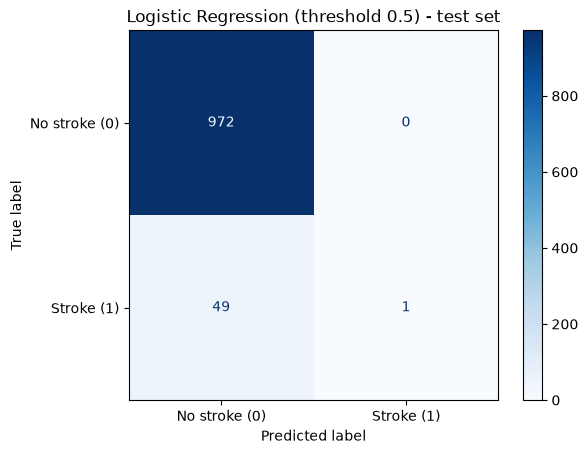

[[972   0]
 [ 49   1]]


In [8]:
# confusion matrix of the default Logistic Regression
pred_lr = lr_default.predict(X_test_s)
cm = confusion_matrix(y_test, pred_lr)
ConfusionMatrixDisplay(cm, display_labels=['No stroke (0)', 'Stroke (1)']).plot(cmap='Blues')
plt.title('Logistic Regression (threshold 0.5) - test set')
plt.show()
print(cm)

**What the plot shows:** the model caught only 1 stroke and missed 49. It made no false alarms (0 healthy patients flagged).

**Question (a):** Compare the accuracy of the baseline and Logistic Regression. What do you conclude?

**Answer:** The baseline has 0.9511 and Logistic Regression has 0.9521, so they are almost the same. The baseline never finds a stroke and Logistic Regression finds only 1 out of 50. The high accuracy comes only from 95% of patients being healthy. So accuracy cannot tell a useless model from a slightly better one here.

**Question (b):** What does a false negative mean for the hospital, and which numbers should we trust instead of accuracy?

**Answer:** A false negative is a patient who will have a stroke but is told they are fine. They get no checkup and no treatment, so it is the worst mistake in this problem. Logistic Regression has 49 false negatives out of 50 strokes. I would trust recall (0.02), PR AUC (0.2692 against 0.0489 for the baseline), ROC AUC (0.8394) and F1 instead of accuracy. The precision of 1.0 looks good but it comes from only one positive prediction, so I don't trust it.

## Part 2 — Underfitting, Overfitting, Bias and Variance

### Task 2.1 — Validation curve

In [9]:
# Task 2.1 - validation curve for Decision Tree max_depth
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
depths = list(range(1, 16)) + [None]

rows = []
for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    dt.fit(X_train, y_train)
    train_auc = roc_auc_score(y_train, dt.predict_proba(X_train)[:, 1])
    cv_auc = cross_val_score(dt, X_train, y_train, cv=skf, scoring='roc_auc').mean()
    rows.append({'max_depth': 'None' if d is None else d, 'Train AUC': train_auc, 'CV AUC': cv_auc})

val_table = pd.DataFrame(rows).set_index('max_depth')
print(val_table.round(4))
best_depth = val_table['CV AUC'].idxmax()
print()
print('Best depth by CV AUC:', best_depth, '| CV AUC =', round(val_table['CV AUC'].max(), 4))

           Train AUC  CV AUC
max_depth                   
1             0.7171  0.7317
2             0.8208  0.8168
3             0.8375  0.8161
4             0.8580  0.8180
5             0.8758  0.7921
6             0.9026  0.7585
7             0.9276  0.7385
8             0.9494  0.7138
9             0.9678  0.6812
10            0.9808  0.6414
11            0.9910  0.6108
12            0.9959  0.6126
13            0.9985  0.5955
14            0.9996  0.5889
15            0.9999  0.5779
None          1.0000  0.5644

Best depth by CV AUC: 4 | CV AUC = 0.818


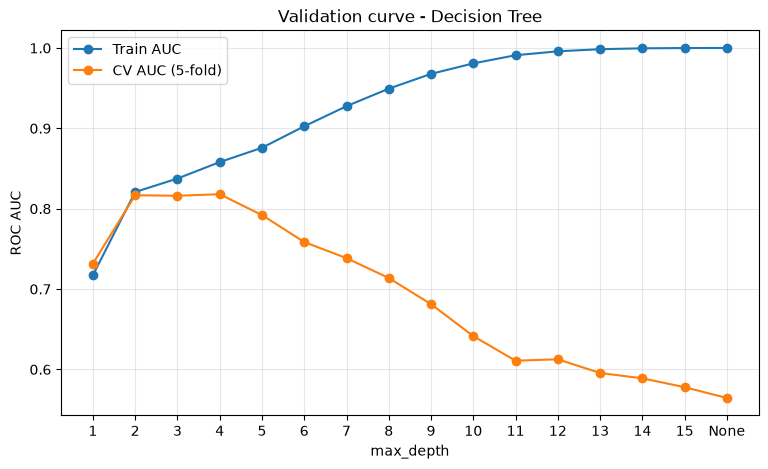

In [10]:
# plot both curves (None is drawn as the last point)
xs = list(range(1, len(depths) + 1))
plt.figure(figsize=(9, 5))
plt.plot(xs, val_table['Train AUC'], marker='o', label='Train AUC')
plt.plot(xs, val_table['CV AUC'], marker='o', label='CV AUC (5-fold)')
plt.xticks(xs, val_table.index.astype(str))
plt.xlabel('max_depth')
plt.ylabel('ROC AUC')
plt.title('Validation curve - Decision Tree')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**What the plot shows:** the train AUC keeps going up with depth and reaches 1.0 at depth None. The CV AUC goes up until depth 4 (0.8180), then falls to 0.5644 at depth None. After depth 4 the gap between the two curves keeps growing.

**Question (a):** Which depths underfit, which overfit, and which depth would I choose?

**Answer:** Depth 1 underfits: train AUC 0.7171 and CV AUC 0.7317, both low. Depths 2 to 4 are the good zone. For example depth 3 has train AUC 0.8375 and CV AUC 0.8161, which are close to each other. From about depth 5 the tree overfits. Depth None has train AUC 1.0000 but CV AUC only 0.5644. The best CV AUC is at depth 4 (0.8180), but depth 3 is only 0.002 lower and simpler, so I would choose depth 3.

### Task 2.2 — Learning curves

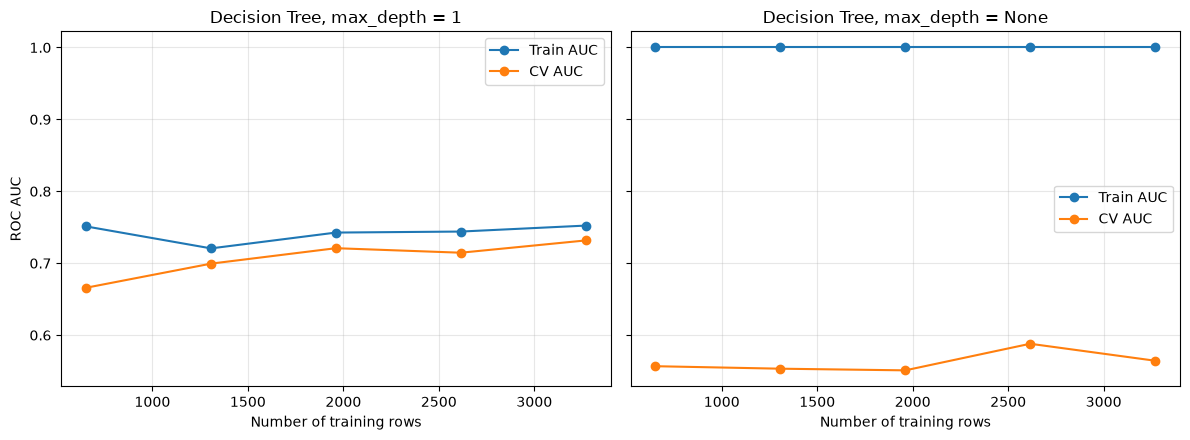

,max_depth,Train rows,Train AUC,CV AUC
0,1,653,0.7512,0.6659
1,1,1307,0.7206,0.6994
2,1,1961,0.7426,0.7209
3,1,2615,0.7440,0.7146
4,1,3269,0.7523,0.7317
5,None,653,1.0000,0.5568
6,None,1307,1.0000,0.5533
7,None,1961,1.0000,0.5510
8,None,2615,1.0000,0.5880
9,None,3269,1.0000,0.5644


In [11]:
# Task 2.2 - learning curves for depth 1 and depth None
sizes = np.linspace(0.2, 1.0, 5)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
lc_rows = []
for ax, d in zip(axes, [1, None]):
    tr_sizes, tr_sc, va_sc = learning_curve(
        DecisionTreeClassifier(max_depth=d, random_state=SEED), X_train, y_train,
        train_sizes=sizes, cv=skf, scoring='roc_auc', shuffle=True, random_state=SEED)
    ax.plot(tr_sizes, tr_sc.mean(axis=1), marker='o', label='Train AUC')
    ax.plot(tr_sizes, va_sc.mean(axis=1), marker='o', label='CV AUC')
    ax.set_title(f'Decision Tree, max_depth = {d}')
    ax.set_xlabel('Number of training rows')
    ax.grid(alpha=0.3)
    ax.legend()
    for n, a, b in zip(tr_sizes, tr_sc.mean(axis=1), va_sc.mean(axis=1)):
        lc_rows.append({'max_depth': str(d), 'Train rows': n, 'Train AUC': a, 'CV AUC': b})
axes[0].set_ylabel('ROC AUC')
plt.tight_layout()
plt.show()
pd.DataFrame(lc_rows).round(4)

**What the plots show:** for depth 1, at the full size of 3,269 rows the train AUC is 0.7523 and the CV AUC is 0.7317. Both are low and close to each other. For depth None the train AUC stays at 1.0 for every size, but the CV AUC stays around 0.55 to 0.59 (0.5644 at 3,269 rows).

**Question (b):** How can you tell high bias from high variance? Will more training rows fix either one?

**Answer:** High bias (depth 1): train and CV curves are both low and very close, so the model is too simple to learn the pattern. High variance (depth None): the train curve is perfect (1.0) but the CV curve is far below it (about 0.56), so there is a big gap. More rows will not fix high bias, because both curves are already flat at a low value. More rows can help high variance a little, but the CV curve of depth None hardly moved from 653 to 3,269 rows (0.5568 to 0.5644). So it would need a lot more data, and limiting the depth is a better fix.

### Task 2.3 — Measure variance directly

In [12]:
# Task 2.3 - measure variance directly with 40 bootstrap samples
n_boot = 40
rng = np.random.default_rng(SEED)
boot_idx = [rng.choice(len(X_train), len(X_train), replace=True) for _ in range(n_boot)]

var_rows = []
for d in [1, 3, None]:
    probs = np.zeros((n_boot, len(X_test)))
    for b, idx in enumerate(boot_idx):
        tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
        tree.fit(X_train.iloc[idx], y_train.iloc[idx])
        probs[b] = tree.predict_proba(X_test)[:, 1]

    mean_var = probs.var(axis=0).mean()
    single_aucs = [roc_auc_score(y_test, p) for p in probs]
    avg_auc = roc_auc_score(y_test, probs.mean(axis=0))
    var_rows.append({'max_depth': 'None' if d is None else d,
                     'Mean variance of predictions': mean_var,
                     'Mean AUC of single trees': np.mean(single_aucs),
                     'AUC of averaged prediction': avg_auc})

var_table = pd.DataFrame(var_rows).set_index('max_depth')
var_table.round(4)

,Mean variance of predictions,Mean AUC of single trees,AUC of averaged prediction
max_depth,,,
1,0.0007,0.7623,0.8132
3,0.0018,0.7930,0.8351
None,0.0437,0.5554,0.7429


**What the table shows:** the mean variance of the predicted probabilities is 0.0007 for depth 1, 0.0018 for depth 3 and 0.0437 for depth None. The mean AUC of the single trees is 0.7623, 0.7930 and 0.5554. The AUC of the averaged prediction is 0.8132, 0.8351 and 0.7429.

**Question (c):** How does variance change with depth? What happens to the AUC of the averaged prediction? Link it to Random Forest.

**Answer:** Variance grows with depth. Depth None has about 24 times the variance of depth 3 (0.0437 against 0.0018). Averaging the 40 trees improves the AUC for all three depths: depth 1 goes from 0.7623 to 0.8132, depth 3 from 0.7930 to 0.8351 and depth None from 0.5554 to 0.7429. The biggest jump is for depth None (+0.19), because its trees have the most variance and averaging cancels a lot of it. This is what Random Forest does: it averages many deep trees trained on bootstrap samples. Averaging reduces variance but not bias, so the averaged depth None trees (0.7429) are still below depth 3 (0.8351).

**Question (d):** In my own words, what is the bias-variance trade-off and where do depth 1, 3 and None sit?

**Answer:** A simple model has high bias: it misses the real pattern, but it gives about the same predictions whatever training data it sees. A complex model has low bias but high variance: it fits the training data very well, but its predictions change a lot when the training data changes a little. We want the middle. Depth 1 sits on the high bias side (low variance 0.0007, low AUC). Depth 3 is close to the balance (variance 0.0018, best AUC among the three). Depth None sits on the high variance side (variance 0.0437, train AUC 1.0 but test AUC around 0.56).

## Part 3 — ROC, AUC, Precision-Recall and Thresholds

### Task 3.1 — Compare models with curves

In [13]:
# 1
def make_lr(**kw):
    return LogisticRegression(max_iter=1000, random_state=SEED, **kw)

def make_rf(**kw):
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1, **kw)

lr3 = make_lr().fit(X_train_s, y_train)
dt3 = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train, y_train)
rf3 = make_rf().fit(X_train, y_train)

test_proba = {'Logistic Regression': lr3.predict_proba(X_test_s)[:, 1],
              'Decision Tree (depth 3)': dt3.predict_proba(X_test)[:, 1],
              'Random Forest': rf3.predict_proba(X_test)[:, 1]}

curve_table = pd.DataFrame({m: {'ROC AUC': roc_auc_score(y_test, p),
                                'Average precision': average_precision_score(y_test, p)}
                            for m, p in test_proba.items()}).T
print('No-skill level (stroke rate in test):', round(y_test.mean(), 4))
curve_table.round(4)

No-skill level (stroke rate in test): 0.0489


,ROC AUC,Average precision
Logistic Regression,0.8394,0.2692
Decision Tree (depth 3),0.7956,0.1621
Random Forest,0.8224,0.2255


**What the table shows:** Logistic Regression is best on both numbers (ROC AUC 0.8394, average precision 0.2692). Random Forest is second (0.8224 and 0.2255) and the depth 3 tree is last (0.7956 and 0.1621). All three average precisions are above the no-skill level of 0.0489.

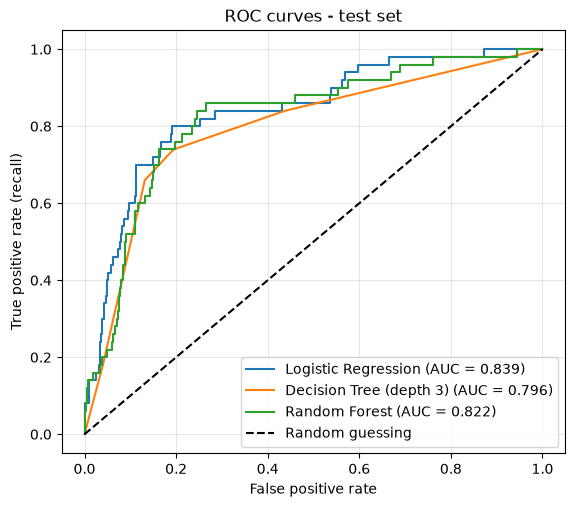

In [14]:
# 2
plt.figure(figsize=(6.5, 5.5))
for m, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f'{m} (AUC = {roc_auc_score(y_test, p):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate (recall)')
plt.title('ROC curves - test set')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

**What the plot shows:** all three curves are above the random-guessing diagonal. Logistic Regression has the highest AUC (0.839) and the three models do not look very different.

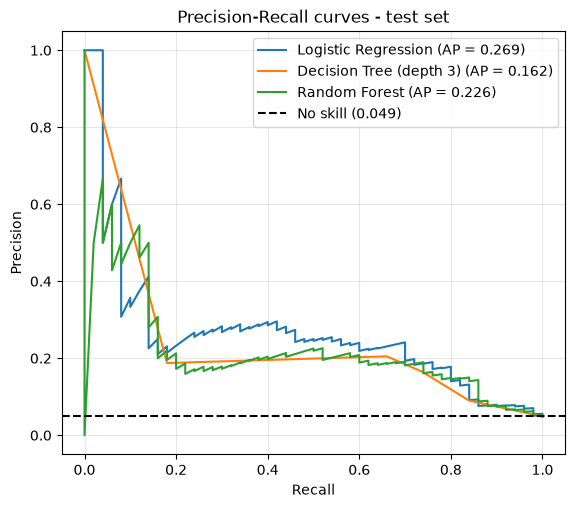

In [15]:
# 3
plt.figure(figsize=(6.5, 5.5))
for m, p in test_proba.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    plt.plot(rec, prec, label=f'{m} (AP = {average_precision_score(y_test, p):.3f})')
plt.axhline(y_test.mean(), color='k', linestyle='--', label=f'No skill ({y_test.mean():.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall curves - test set')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**What the plot shows:** the PR curves are very far from the top right corner. Precision is low for all models, even though the ROC curves looked good. The curves are above the no-skill line (0.049), and Logistic Regression is best with average precision 0.269.

### Task 3.2 — Choose a decision threshold

In [16]:
# Task 3.2 - threshold from TRAIN data only (out-of-fold probabilities)
# a pipeline is used so the scaler is re-fitted inside every fold
pipe = make_pipeline(StandardScaler(), make_lr())
oof_proba = cross_val_predict(pipe, X_train, y_train, cv=skf, method='predict_proba')[:, 1]

# highest threshold whose out-of-fold recall is at least 0.80
fpr_o, tpr_o, thr_o = roc_curve(y_train, oof_proba)
chosen_thr = thr_o[np.where(tpr_o >= 0.80)[0][0]]

oof_pred = (oof_proba >= chosen_thr).astype(int)
print('Chosen threshold      :', round(chosen_thr, 4))
print('Out-of-fold recall    :', round(recall_score(y_train, oof_pred), 4))
print('Out-of-fold precision :', round(precision_score(y_train, oof_pred), 4))
assert recall_score(y_train, oof_pred) >= 0.80

Chosen threshold      : 0.0509
Out-of-fold recall    : 0.804
Out-of-fold precision : 0.1358


**What I see:** the highest threshold that gives out-of-fold recall of at least 0.80 is 0.0509. At this threshold the out-of-fold recall is 0.804 and the precision is 0.1358.

Test recall    : 0.82
Test precision : 0.1353
Patients flagged: 303 of 1022
True strokes caught: 41 | missed: 9
False alarms   : 262


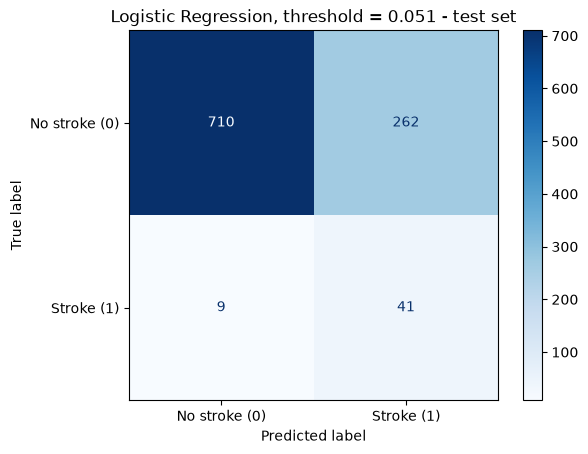

[[710 262]
 [  9  41]]


In [17]:
# apply the threshold to the test probabilities
lr_proba = test_proba['Logistic Regression']
pred_thr = (lr_proba >= chosen_thr).astype(int)
cm_thr = confusion_matrix(y_test, pred_thr)
tn, fp, fn, tp = cm_thr.ravel()

print('Test recall    :', round(recall_score(y_test, pred_thr), 4))
print('Test precision :', round(precision_score(y_test, pred_thr), 4))
print('Patients flagged:', pred_thr.sum(), 'of', len(y_test))
print('True strokes caught:', tp, '| missed:', fn)
print('False alarms   :', fp)

ConfusionMatrixDisplay(cm_thr, display_labels=['No stroke (0)', 'Stroke (1)']).plot(cmap='Blues')
plt.title(f'Logistic Regression, threshold = {chosen_thr:.3f} - test set')
plt.show()
print(cm_thr)

**What the result shows:** on the test set the threshold 0.0509 gives recall 0.82 (41 of 50 strokes caught, 9 missed) and precision 0.1353. It flags 303 of 1,022 patients and 262 of them are false alarms. The recall on the test set (0.82) is close to the 0.804 I got on the train data, so the threshold carried over well.

**Question (a):** In Part 1 recall was very low but ROC AUC was 0.84. How can both be true?

**Answer:** ROC AUC does not use any single threshold. It measures how well the model ranks patients: it is the chance that a random stroke patient gets a higher score than a random healthy patient. An AUC of 0.8394 means the ranking is good. But recall is measured at the 0.5 threshold. Only about 5% of the patients have a stroke, so the model's probabilities are small for almost everybody, and even stroke patients rarely get a probability above 0.5. That is why only 1 of 50 was caught. The ranking was fine, the threshold was wrong. With threshold 0.0509 the same model catches 41 of 50.

**Question (b):** Which curve is more informative here, ROC or Precision-Recall? Use the no-skill line.

**Answer:** The Precision-Recall curve is more informative. There are about 20 healthy patients for every stroke patient, so many false positives only move the false positive rate a little, and the ROC curve looks good. Logistic Regression has ROC AUC 0.839 and that looks strong. The PR curve shows the real problem: its average precision is 0.2692 and the no-skill line is only 0.0489, so precision is low. It also shows a bigger difference between the models (0.2692 for Logistic Regression and 0.1621 for the tree) than the ROC AUC does (0.8394 and 0.7956).

**Question (c):** What is the price of the higher recall? Is it acceptable?

**Answer:** The price is false alarms. To catch 41 strokes, 303 patients are flagged and 262 of them are healthy (about 6.4 false alarms per stroke caught, precision 0.135). Yes, it is acceptable: a missed stroke can kill or disable a patient, while a false alarm usually means only an extra checkup (blood pressure, blood test). Recall went from 0.02 to 0.82. No, it is not so good: almost 30% of all patients get flagged, which costs money, uses up doctors' time and worries healthy people. And 9 strokes are still missed. I think it is acceptable for a first screening step if the follow-up test is cheap.

## Part 4 — Undersampling, Oversampling and SMOTE

### Task 4.1 — Compare the methods

In [18]:
# Task 4.1 - rebalancing methods (resample the TRAIN set only)
methods = ['No resampling', 'class_weight=balanced', 'Random undersampling',
           'Random oversampling', 'SMOTE']
samplers = {'Random undersampling': lambda: RandomUnderSampler(random_state=SEED),
            'Random oversampling': lambda: RandomOverSampler(random_state=SEED),
            'SMOTE': lambda: SMOTE(random_state=SEED)}
setups = {'Logistic Regression': (X_train_s, X_test_s, make_lr),
          'Random Forest': (X_train, X_test, make_rf)}

rows = []
for mname, (Xtr, Xte, maker) in setups.items():
    for method in methods:
        if method == 'class_weight=balanced':
            model = maker(class_weight='balanced')
            Xr, yr = Xtr, y_train
        elif method == 'No resampling':
            model = maker()
            Xr, yr = Xtr, y_train
        else:
            Xr, yr = samplers[method]().fit_resample(Xtr, y_train)
            model = maker()
        res = evaluate(model, Xr, yr, Xte, y_test)
        rows.append({'Model + method': f'{mname} - {method}',
                     'Train rows': len(yr), 'Train strokes': int(np.sum(yr)),
                     'Precision': res['Precision'], 'Recall': res['Recall'], 'F1': res['F1'],
                     'ROC AUC': res['ROC AUC'], 'PR AUC': res['PR AUC']})

resample_table = pd.DataFrame(rows).set_index('Model + method')
resample_table.round(4)

,Train rows,Train strokes,Precision,Recall,F1,ROC AUC,PR AUC
Model + method,,,,,,,
Logistic Regression - No resampling,4087,199,1.0000,0.02,0.0392,0.8394,0.2692
Logistic Regression - class_weight=balanced,4087,199,0.1347,0.80,0.2305,0.8395,0.2595
Logistic Regression - Random undersampling,398,199,0.1246,0.82,0.2164,0.8352,0.2338
Logistic Regression - Random oversampling,7776,3888,0.1333,0.80,0.2286,0.8385,0.2646
Logistic Regression - SMOTE,7776,3888,0.1338,0.80,0.2292,0.8406,0.2876
Random Forest - No resampling,4087,199,0.0000,0.00,0.0000,0.8224,0.2255
Random Forest - class_weight=balanced,4087,199,0.1895,0.72,0.3000,0.8150,0.1987
Random Forest - Random undersampling,398,199,0.1050,0.84,0.1867,0.8203,0.2030
Random Forest - Random oversampling,7776,3888,0.1882,0.32,0.2370,0.8111,0.1906


**What the table shows:** for Logistic Regression, recall goes from 0.02 (no resampling) to 0.80 to 0.82 with all four methods, and precision goes from 1.0 to 0.12 to 0.13. ROC AUC stays between 0.8352 and 0.8406. For Random Forest, recall without resampling is 0.0. It is 0.30 with class weights, 0.32 with oversampling, 0.20 with SMOTE and 0.84 with undersampling. Its ROC AUC goes down with resampling, from 0.8224 to 0.7668 with SMOTE.

### Task 4.2 — The classic mistake

In [19]:
# Task 4.2 - the classic mistake: SMOTE on ALL the data, then split
X_all = X.fillna(X.median())            # SMOTE cannot take missing values
X_sm, y_sm = SMOTE(random_state=SEED).fit_resample(X_all, y)
print('After SMOTE on all data:', X_sm.shape, '| strokes:', int(y_sm.sum()))

Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(X_sm, y_sm, test_size=0.2,
                                              random_state=SEED, stratify=y_sm)
res_wrong = evaluate(make_rf(), Xw_tr, yw_tr, Xw_te, yw_te)

# correct order result from Task 4.1 (Random Forest + SMOTE)
correct = resample_table.loc['Random Forest - SMOTE']

wrong_table = pd.DataFrame([
    {'Order': 'Wrong (SMOTE, then split)', 'Test rows': len(yw_te), 'Test strokes': int(yw_te.sum()),
     'Precision': res_wrong['Precision'], 'Recall': res_wrong['Recall'], 'F1': res_wrong['F1'],
     'ROC AUC': res_wrong['ROC AUC'], 'PR AUC': res_wrong['PR AUC']},
    {'Order': 'Correct (split, then SMOTE)', 'Test rows': len(y_test), 'Test strokes': int(y_test.sum()),
     'Precision': correct['Precision'], 'Recall': correct['Recall'], 'F1': correct['F1'],
     'ROC AUC': correct['ROC AUC'], 'PR AUC': correct['PR AUC']}]).set_index('Order')
wrong_table.round(4)

After SMOTE on all data: (9720, 15) | strokes: 4860


,Test rows,Test strokes,Precision,Recall,F1,ROC AUC,PR AUC
Order,,,,,,,
"Wrong (SMOTE, then split)",1944,972,0.9290,0.9424,0.9356,0.9811,0.9761
"Correct (split, then SMOTE)",1022,50,0.1266,0.2000,0.1550,0.7668,0.1187


**What the table shows:** the wrong order gives recall 0.9424, precision 0.9290, ROC AUC 0.9811 and PR AUC 0.9761. The correct order gives recall 0.2000, precision 0.1266, ROC AUC 0.7668 and PR AUC 0.1187. Also note the test sets are different: the wrong-order test set has 1,944 rows and 972 strokes (50%), and the correct one has 1,022 rows and 50 strokes (4.9%).

**Question (a):** For Logistic Regression, what changed after resampling and what did not?

**Answer:** Recall changed a lot: it went from 0.02 to 0.80 (class weights, oversampling, SMOTE) and 0.82 (undersampling). Precision fell from 1.0 to about 0.12 to 0.13. The 1.0 was only one correct prediction, and now many healthy patients are flagged as well. ROC AUC did not change: 0.8394 before and 0.8352 to 0.8406 after. PR AUC also stayed in the same range (0.2338 to 0.2876 against 0.2692). The reason is that Logistic Regression is a simple model. Resampling mostly shifts where its probabilities sit, so the 0.5 cut now catches more strokes, but the order of the patients (the ranking) stays almost the same. It is like moving along the same ROC curve and not getting a better curve.

**Question (b):** Did Random Forest react in the same way? One difference and one reason.

**Answer:** No. With Logistic Regression all four methods gave recall of about 0.80, but Random Forest was different: class weights gave only 0.30, oversampling 0.32 and SMOTE 0.20, and only undersampling gave a high recall (0.84). Also its ROC AUC fell with SMOTE (0.8224 to 0.7668) while Logistic Regression's did not change. A possible reason is that Random Forest is very flexible. With oversampling it sees the same stroke rows many times, and with SMOTE it sees invented rows, so it fits them very closely and learns patterns that do not hold for real patients. Undersampling worked better for recall because the forest sees only 398 rows and about as many strokes as healthy patients, but its precision is low (0.1050).

**Question (c):** Why are the wrong-order numbers so good, and why can't they be trusted? What leaks from where?

**Answer:** The wrong-order numbers (ROC AUC 0.9811, recall 0.9424) are much higher than the correct ones (0.7668 and 0.2000). The reason is leakage. When SMOTE runs on all the data first, it creates synthetic stroke rows between real stroke patients, and then the random split puts these rows into both train and test. So a synthetic test row has its real neighbours or near copies in the train set, and the forest just recognises them. The information leaks from the test patients into the train set through the synthetic rows. Also the test set is now 50% strokes, mostly synthetic, so it is a much easier problem than the real one with 4.9% strokes. These numbers do not say anything about new real patients.

**Question (d):** Which rebalancing approach would I pick for this hospital?

**Answer:** I would pick `class_weight='balanced'` with Logistic Regression. It gives recall 0.80, precision 0.1347 and ROC AUC 0.8395, which is about the same as oversampling and SMOTE, and it needs no extra rows and no extra library. Undersampling throws away about 90% of the train rows (4,087 down to 398) and has to be redone on a different sample. Oversampling doubles the train set to 7,776 rows with copies. SMOTE makes fake patients, and it also makes values like 0.4 for yes/no columns such as hypertension. SMOTE had the best PR AUC for Logistic Regression (0.2876) but the difference is small. For my final answer I use a threshold chosen on the train data instead, which is also simple and lets me set the recall target directly.

## Part 5 — Noisy Data

I damage the TRAIN data on purpose and measure the ROC AUC on the clean test set. The four models are Logistic Regression, Decision Tree (depth 3), Decision Tree (no limit) and Random Forest.

### Task 5.1 — Label noise

In [20]:
# Part 5 - setup for the noise experiments
model_makers = {'Logistic Regression': make_lr,
                'Decision Tree (depth 3)': lambda: DecisionTreeClassifier(max_depth=3, random_state=SEED),
                'Decision Tree (no limit)': lambda: DecisionTreeClassifier(random_state=SEED),
                'Random Forest': make_rf}

def test_auc(name, Xtr, Xtr_s, ytr, Xte, Xte_s):
    """train one model on (possibly damaged) training data, return ROC AUC on the clean test set"""
    model = model_makers[name]()
    if name == 'Logistic Regression':
        model.fit(Xtr_s, ytr)
        return roc_auc_score(y_test, model.predict_proba(Xte_s)[:, 1])
    model.fit(Xtr, ytr)
    return roc_auc_score(y_test, model.predict_proba(Xte)[:, 1])

def flip_labels(y, frac, rng):
    """flip a fraction of the labels at random (0 -> 1, 1 -> 0)"""
    y_new = np.array(y).copy()
    idx = rng.choice(len(y_new), size=int(round(frac * len(y_new))), replace=False)
    y_new[idx] = 1 - y_new[idx]
    return y_new

             Logistic Regression  Decision Tree (depth 3)  Decision Tree (no limit)  Random Forest
Label noise                                                                                       
0.00                      0.8394                   0.7956                    0.5797         0.8224
0.05                      0.8241                   0.8014                    0.5529         0.8034
0.10                      0.8133                   0.8029                    0.5105         0.7592
0.20                      0.7743                   0.7260                    0.5045         0.6831


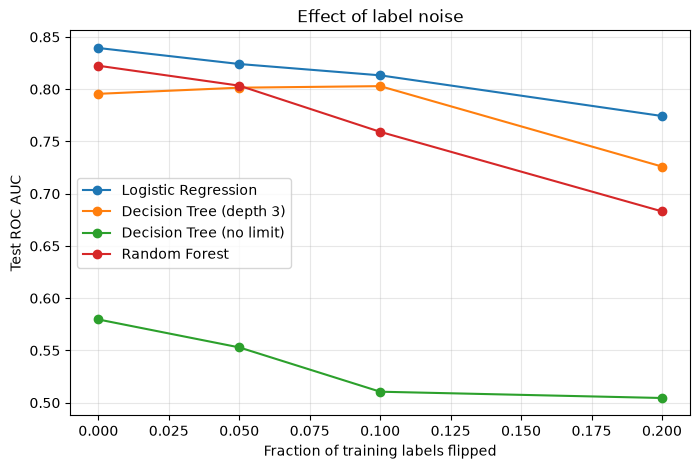

In [21]:
# Task 5.1 - label noise
fractions = [0, 0.05, 0.10, 0.20]
label_rows = {}
for frac in fractions:
    reps = 1 if frac == 0 else 5
    scores = {m: [] for m in model_makers}
    for r in range(reps):
        rng = np.random.default_rng(SEED + r)
        y_noisy = flip_labels(y_train, frac, rng)
        for m in model_makers:
            scores[m].append(test_auc(m, X_train, X_train_s, y_noisy, X_test, X_test_s))
    label_rows[frac] = {m: np.mean(v) for m, v in scores.items()}

label_table = pd.DataFrame(label_rows).T
label_table.index.name = 'Label noise'
print(label_table.round(4))

label_table.plot(marker='o', figsize=(8, 5))
plt.xlabel('Fraction of training labels flipped')
plt.ylabel('Test ROC AUC')
plt.title('Effect of label noise')
plt.grid(alpha=0.3)
plt.show()

**What the table and plot show:** with no noise the AUCs are 0.8394 (Logistic Regression), 0.7956 (tree depth 3), 0.5797 (tree no limit) and 0.8224 (Random Forest). With 20% flipped labels they are 0.7743, 0.7260, 0.5045 and 0.6831. Random Forest falls the most and its line drops fast after 5%.

### Task 5.2 — Feature noise

                     Logistic Regression  Decision Tree (depth 3)  Decision Tree (no limit)  Random Forest
Feature noise level                                                                                       
0.0                               0.8394                   0.7956                    0.5797         0.8224
0.5                               0.8337                   0.7995                    0.5608         0.8140
1.0                               0.8098                   0.7610                    0.5283         0.7870
2.0                               0.7695                   0.6942                    0.5309         0.7406


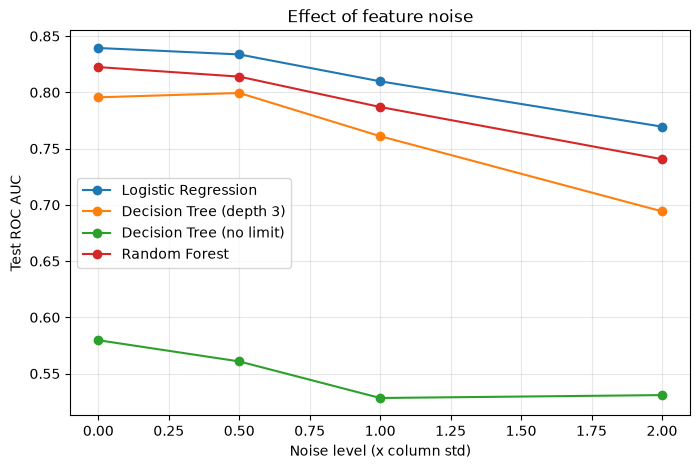

In [22]:
# Task 5.2 - feature noise on age, avg_glucose_level and bmi (train only)
noisy_cols = ['age', 'avg_glucose_level', 'bmi']
col_std = X_train[noisy_cols].std()

levels = [0, 0.5, 1, 2]
feat_rows = {}
for level in levels:
    scores = {m: [] for m in model_makers}
    for r in range(5):
        rng = np.random.default_rng(SEED + r)
        X_noisy = X_train.copy()
        for c in noisy_cols:
            X_noisy[c] = X_noisy[c] + rng.normal(size=len(X_noisy)) * col_std[c] * level
        # scaler is fitted on the noisy training data
        sc = StandardScaler().fit(X_noisy)
        X_noisy_s, X_test_s_n = sc.transform(X_noisy), sc.transform(X_test)
        for m in model_makers:
            scores[m].append(test_auc(m, X_noisy, X_noisy_s, y_train, X_test, X_test_s_n))
    feat_rows[level] = {m: np.mean(v) for m, v in scores.items()}

feat_table = pd.DataFrame(feat_rows).T
feat_table.index.name = 'Feature noise level'
print(feat_table.round(4))

feat_table.plot(marker='o', figsize=(8, 5))
plt.xlabel('Noise level (x column std)')
plt.ylabel('Test ROC AUC')
plt.title('Effect of feature noise')
plt.grid(alpha=0.3)
plt.show()

**What the table and plot show:** at noise level 2 the AUCs are 0.7695 (Logistic Regression), 0.6942 (tree depth 3), 0.5309 (tree no limit) and 0.7406 (Random Forest). The tree of depth 3 falls the most (0.7956 to 0.6942). Level 0.5 hardly changes anything.

### Task 5.3 — SMOTE and noisy labels

In [23]:
# Task 5.3 - SMOTE when 10% of the training labels are wrong
rows = []
for r in range(3):
    rng = np.random.default_rng(SEED + r)
    y_noisy = flip_labels(y_train, 0.10, rng)
    for mname, (Xtr, Xte, maker) in setups.items():
        # without SMOTE
        res = evaluate(maker(), Xtr, y_noisy, Xte, y_test)
        rows.append({'Model': mname, 'SMOTE': 'No', 'PR AUC': res['PR AUC'], 'ROC AUC': res['ROC AUC']})
        # with SMOTE (applied after the noise is added)
        Xr, yr = SMOTE(random_state=SEED).fit_resample(Xtr, y_noisy)
        res = evaluate(maker(), Xr, yr, Xte, y_test)
        rows.append({'Model': mname, 'SMOTE': 'Yes', 'PR AUC': res['PR AUC'], 'ROC AUC': res['ROC AUC']})

smote_noise = pd.DataFrame(rows).groupby(['Model', 'SMOTE']).mean()
smote_noise.round(4)

PR AUC  ROC AUC
Model               SMOTE                 
Logistic Regression No     0.2174   0.8140
                    Yes    0.2259   0.8158
Random Forest       No     0.1543   0.7482
                    Yes    0.0607   0.5967

**What the table shows:** for Logistic Regression SMOTE barely changes anything (PR AUC 0.2174 to 0.2259 and ROC AUC 0.8140 to 0.8158). For Random Forest SMOTE makes it much worse: PR AUC goes from 0.1543 to 0.0607 and ROC AUC from 0.7482 to 0.5967.

In [24]:
# Evidence for Question (c): who is in the "stroke" class after 10% of labels are flipped?
# (first random draw, same seed as in the Task 5.3 loop)
rng = np.random.default_rng(SEED + 0)
y_noisy = flip_labels(y_train, 0.10, rng)
y_true = np.array(y_train)

n_minority = int((y_noisy == 1).sum())
n_real = int(((y_noisy == 1) & (y_true == 1)).sum())
n_fake = int(((y_noisy == 1) & (y_true == 0)).sum())
print('Rows labelled stroke after noise :', n_minority)
print('  real strokes                   :', n_real)
print('  healthy patients, label flipped:', n_fake, f'({n_fake / n_minority * 100:.1f}% of the minority class)')


Rows labelled stroke after noise : 572
  real strokes                   : 181
  healthy patients, label flipped: 391 (68.4% of the minority class)


**Question (a):** Which model is most damaged by noise and which is most stable?

**Answer:** Random Forest is the most damaged by label noise: at 20% flips its AUC falls from 0.8224 to 0.6831 (a drop of 0.139). Logistic Regression is the most stable: it falls from 0.8394 to 0.7743 (a drop of 0.065) and is still the best model at 20%. The depth 3 tree is close to it (a drop of 0.070). The unlimited tree dropped by 0.075 but it was already near 0.5, so there was not much left to lose. This matches Part 2. Models with low bias and high variance, like deep trees and forests, can fit anything, including the wrong labels, so they learn the noise. Simple models with high bias are too rigid to follow the noise. For feature noise at level 2 the depth 3 tree drops the most (0.101), while Logistic Regression drops 0.070 and Random Forest 0.082.

**Question (b):** Which hurts more, label noise or feature noise of a comparable level?

**Answer:** Label noise hurt a little more. At the highest levels the mean AUC of the four models fell from 0.7593 to 0.6720 with label noise (a drop of 0.087) and to 0.6838 with feature noise (a drop of 0.075). The difference is mostly because of Random Forest. For the other models it is mixed, so I would say they are not far apart. A reason is that a wrong label tells the model the wrong answer directly, and with only 199 strokes in train the flipped labels matter a lot. Feature noise only blurs three of the 15 columns and the other columns stay clean. Also, "comparable level" is my own judgement, so this is not exact.

**Question (c):** What did SMOTE do to each model when the labels were noisy? Why can it amplify label noise?

**Answer:** For Logistic Regression SMOTE did almost nothing (ROC AUC 0.8140 to 0.8158). For Random Forest it hurt a lot (ROC AUC 0.7482 to 0.5967, PR AUC 0.1543 to 0.0607). The reason is how many labels are wrong in the minority class. The check above (first random draw, 10% flips) shows that train had 572 "stroke" rows after the noise, but only 181 of them were real strokes and 391 were healthy patients with a flipped label. So most of the minority class is fake. SMOTE makes new rows between these minority rows, so it creates many more fake stroke points in the healthy region, and the forest learns them. SMOTE cannot tell which minority labels are wrong, it just copies the pattern of whatever is labelled 1.

## Part 6 — Final Decision and Conclusion

My final choice is **Logistic Regression (scaled) with a threshold of 0.0509**, which I picked from out-of-fold predictions on the train set so that recall is at least 0.80. I do not use any resampling. Below is the comparison with the default threshold 0.5 on the test set.

In [25]:
# Part 6 - final decision: Logistic Regression (scaled) + threshold chosen on TRAIN data
def summarize(pred):
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {'Precision': precision_score(y_test, pred, zero_division=0),
            'Recall': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred),
            'False alarms': int(fp),
            'Missed strokes': int(fn)}

final_table = pd.DataFrame([summarize((lr_proba >= 0.5).astype(int)),
                            summarize((lr_proba >= chosen_thr).astype(int))],
                           index=['Threshold 0.5', f'Chosen threshold ({chosen_thr:.3f})'])
final_table.round(4)

,Precision,Recall,F1,False alarms,Missed strokes
Threshold 0.5,1.0000,0.02,0.0392,0,49
Chosen threshold (0.051),0.1353,0.82,0.2323,262,9


**What the table shows:** at 0.5 the model flags just 1 patient (precision 1.0, recall 0.02), has 0 false alarms and misses 49 strokes. With the chosen threshold, recall is 0.82, precision is 0.1353 and F1 is 0.2323. It has 262 false alarms and 9 missed strokes.

### Executive Summary

I chose Logistic Regression on scaled features with a lower decision threshold (0.0509) and no resampling. On the test set it catches 41 of 50 strokes (recall 0.82) with precision 0.1353 and F1 0.2323, compared with recall 0.02 at the default 0.5 threshold. The price is 262 false alarms, so 303 of 1,022 patients get flagged, which is about 6.4 false alarms for every stroke found. I chose this because missing a stroke is much worse than an extra checkup. To avoid leakage, the median, the scaler and the threshold were all learned from the train data only (the threshold from out-of-fold predictions with the scaler inside a pipeline), and no resampling touched the test set. One limitation is that there are only 50 strokes in the test set, so each patient is worth 2 points of recall and the 0.82 could easily move on another split. Also the threshold depends on the 80% recall target I was given, and a different target would give a different price in false alarms.

### Final Reflection

**(a) What was the most surprising result in this lab?**

**Answer:** That Logistic Regression had 95.2% accuracy but caught only 1 of 50 strokes, with the same ROC AUC (0.8394) as the model that later caught 41 just by changing the threshold. Also the wrong-order SMOTE gave ROC AUC 0.9811, which looked amazing until I understood the leak.

**(b) If you had one more hour, what would you try next?**

**Answer:** I would use repeated cross-validation to get a range for the recall and precision, because 50 strokes in the test set is too few. Then I would try a cost-based threshold, using an estimate of what a false alarm costs against a missed stroke, instead of just the 80% target.